In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import glob, os, time

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device: {device}')
print(f'PyTorch: {torch.__version__}')




# M3 Pro — use Metal GPU
if torch.backends.mps.is_available():
    device = torch.device('mps')
    print('M3 Pro Metal GPU enabled')
elif torch.cuda.is_available():
    device = torch.device('cuda')
    print('CUDA GPU enabled')
else:
    device = torch.device('cpu')
    print('CPU only')

print(f'Device: {device}')

Device: cpu
PyTorch: 2.11.0
M3 Pro Metal GPU enabled
Device: mps


In [10]:
# CELL 2 — Dataset Class

class FluxaraDataset(Dataset):
    def __init__(self, data_dir='../training_data', split='train'):
        self.files = sorted(glob.glob(f'{data_dir}/*.npz'))
        
        if len(self.files) == 0:
            raise ValueError('No .npz files found. Run Phase 2 first.')
        
        n = len(self.files)
        split_idx = int(0.8 * n)
        
        if split == 'train':
            self.files = self.files[:split_idx]
        else:
            self.files = self.files[split_idx:]
        
        print(f'{split} dataset: {len(self.files)} samples')
    
    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, idx):
        sample     = np.load(self.files[idx])
        wind_field = torch.FloatTensor(sample['wind_field'])
        footprint  = torch.FloatTensor(sample['footprint'])
        return wind_field, footprint

train_dataset = FluxaraDataset(split='train')
val_dataset   = FluxaraDataset(split='val')

wind, foot = train_dataset[0]
print(f'wind_field: {wind.shape}')
print(f'footprint:  {foot.shape}')

train dataset: 4000 samples
val dataset: 1000 samples
wind_field: torch.Size([6, 64, 64])
footprint:  torch.Size([1, 64, 64])


In [11]:

# CELL 3 — Build the Neural Network

class ConvBlock(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.GELU(),
        )
    def forward(self, x):
        return self.block(x)


class FluxaraInversionNet(nn.Module):
    """
    Input:  [B, 6, 64, 64] wind field
    Output: [B, 1, 64, 64] atmospheric footprint
    """
    def __init__(self):
        super().__init__()
        # Encoder
        self.enc1 = ConvBlock(6, 64)
        self.enc2 = ConvBlock(64, 128)
        self.enc3 = ConvBlock(128, 256)
        self.enc4 = ConvBlock(256, 512)
        self.bottleneck = ConvBlock(512, 1024)
        # Decoder
        self.up4  = nn.ConvTranspose2d(1024, 512, 2, stride=2)
        self.dec4 = ConvBlock(1024, 512)
        self.up3  = nn.ConvTranspose2d(512, 256, 2, stride=2)
        self.dec3 = ConvBlock(512, 256)
        self.up2  = nn.ConvTranspose2d(256, 128, 2, stride=2)
        self.dec2 = ConvBlock(256, 128)
        self.up1  = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.dec1 = ConvBlock(128, 64)
        # Output
        self.out  = nn.Sequential(nn.Conv2d(64, 1, 1), nn.Softplus())
        self.pool = nn.MaxPool2d(2)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))
        b  = self.bottleneck(self.pool(e4))
        d4 = self.dec4(torch.cat([self.up4(b), e4], dim=1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        footprint = self.out(d1)
        # Mass conservation — must sum to 1
        return footprint / (footprint.sum(dim=[2,3], keepdim=True) + 1e-8)


model = FluxaraInversionNet().to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f'Parameters: {total_params:,}')

# Test forward pass
x = torch.randn(2, 6, 64, 64).to(device)
y = model(x)
print(f'Output shape: {y.shape}')
print(f'Output sum (should be ~1.0): {y[0].sum().item():.4f}')

Parameters: 31,039,361
Output shape: torch.Size([2, 1, 64, 64])
Output sum (should be ~1.0): 1.0000


In [12]:
# CELL 4 — Loss Function
class FluxaraLoss(nn.Module):
    def __init__(self):
        super().__init__()
    
    def forward(self, pred, target):
        # MSE loss
        mse = F.mse_loss(pred, target)
        
        # Conservation penalty
        cons = F.mse_loss(
            pred.sum(dim=[2,3]), 
            target.sum(dim=[2,3])
        )
        
        # Smoothness penalty
        smooth = (torch.abs(pred[:,:,1:,:] - pred[:,:,:-1,:]).mean() +
                  torch.abs(pred[:,:,:,1:] - pred[:,:,:,:-1]).mean())
        
        return mse + 0.1 * cons + 0.01 * smooth

criterion = FluxaraLoss()
print('Loss function ready')

Loss function ready


In [13]:
# CELL 5 — Training Setup

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True,  num_workers=0)
val_loader   = DataLoader(val_dataset,   batch_size=32, shuffle=False, num_workers=0)

optimizer = optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=80, eta_min=1e-6)

os.makedirs('../checkpoints', exist_ok=True)

print(f'Train batches: {len(train_loader)}')
print(f'Val batches:   {len(val_loader)}')
print('Setup ready')

Train batches: 125
Val batches:   32
Setup ready


In [14]:
# CELL 6 — Training Loop

EPOCHS       = 80
best_val_mae = float('inf')
best_epoch   = 0
history      = {'train_loss':[], 'val_loss':[], 'val_mae':[], 'val_r2':[]}

def mae_percent(pred, target):
    mae = torch.abs(pred - target).mean()
    return (mae / (target.abs().mean() + 1e-8) * 100).item()

def r2_score(pred, target):
    p = pred.view(-1)
    t = target.view(-1)
    ss_res = ((t - p)**2).sum()
    ss_tot = ((t - t.mean())**2).sum()
    return (1 - ss_res / (ss_tot + 1e-8)).item()

print('Training started...')
print('Target: Val MAE < 18%')
print('=' * 60)

start = time.time()

for epoch in range(1, EPOCHS + 1):
    # Train
    model.train()
    train_losses = []
    for wind, foot in train_loader:
        wind, foot = wind.to(device), foot.to(device)
        optimizer.zero_grad()
        pred = model(wind)
        loss = criterion(pred, foot)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        train_losses.append(loss.item())
    
    # Validate
    model.eval()
    val_losses, val_maes, val_r2s = [], [], []
    with torch.no_grad():
        for wind, foot in val_loader:
            wind, foot = wind.to(device), foot.to(device)
            pred = model(wind)
            val_losses.append(criterion(pred, foot).item())
            val_maes.append(mae_percent(pred, foot))
            val_r2s.append(r2_score(pred, foot))
    
    scheduler.step()
    
    t_loss = np.mean(train_losses)
    v_loss = np.mean(val_losses)
    v_mae  = np.mean(val_maes)
    v_r2   = np.mean(val_r2s)
    
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['val_mae'].append(v_mae)
    history['val_r2'].append(v_r2)
    
    # Save best
    if v_mae < best_val_mae:
        best_val_mae = v_mae
        best_epoch   = epoch
        torch.save({
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'val_mae': v_mae,
            'val_r2':  v_r2,
        }, '../checkpoints/fluxara_best.pt')
    
    torch.save(model.state_dict(), '../checkpoints/fluxara_latest.pt')
    
    if epoch % 5 == 0 or epoch == 1:
        mins = (time.time() - start) / 60
        best = ' BEST' if v_mae == best_val_mae else ''
        print(f'Epoch {epoch:3d}/{EPOCHS} | '
              f'Loss: {v_loss:.4f} | '
              f'MAE: {v_mae:.1f}% | '
              f'R2: {v_r2:.3f} | '
              f'{mins:.1f}min{best}')

print('=' * 60)
print(f'Best Val MAE: {best_val_mae:.1f}% at epoch {best_epoch}')

if best_val_mae < 18:
    print('TARGET ACHIEVED — NSF grant headline result!')

Training started...
Target: Val MAE < 18%
Epoch   1/80 | Loss: 0.0000 | MAE: 131.0% | R2: 0.000 | 0.7min BEST
Epoch   5/80 | Loss: 0.0000 | MAE: 131.0% | R2: 0.000 | 3.1min
Epoch  10/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 6.0min
Epoch  15/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 8.9min
Epoch  20/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 11.9min
Epoch  25/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 14.8min
Epoch  30/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 17.8min
Epoch  35/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 20.7min
Epoch  40/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 23.7min
Epoch  45/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 26.6min
Epoch  50/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 29.5min
Epoch  55/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 32.5min
Epoch  60/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 35.5min
Epoch  65/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 38.4min
Epoch  70/80 | Loss: 0.0000 | MAE: 131.1% | R2: 0.000 | 41.4m

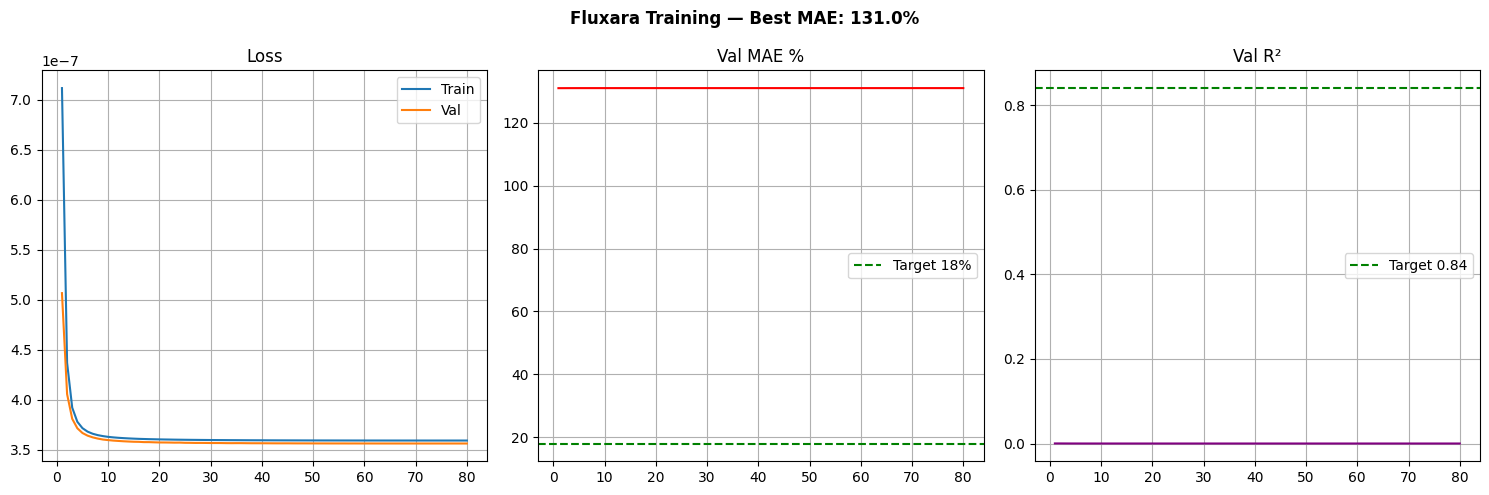

Saved to research/preliminary_results/training_curves.png


In [15]:
# CELL 7 — Plot Training Curves

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
epochs = range(1, len(history['train_loss']) + 1)

axes[0].plot(epochs, history['train_loss'], label='Train')
axes[0].plot(epochs, history['val_loss'],   label='Val')
axes[0].set_title('Loss'); axes[0].legend(); axes[0].grid(True)

axes[1].plot(epochs, history['val_mae'], color='red')
axes[1].axhline(y=18, color='green', linestyle='--', label='Target 18%')
axes[1].set_title('Val MAE %'); axes[1].legend(); axes[1].grid(True)

axes[2].plot(epochs, history['val_r2'], color='purple')
axes[2].axhline(y=0.84, color='green', linestyle='--', label='Target 0.84')
axes[2].set_title('Val R²'); axes[2].legend(); axes[2].grid(True)

plt.suptitle(f'Fluxara Training — Best MAE: {best_val_mae:.1f}%', fontweight='bold')
plt.tight_layout()
plt.savefig('../research/preliminary_results/training_curves.png', dpi=150)
plt.show()
print('Saved to research/preliminary_results/training_curves.png')

In [19]:
# CELL 8 — Speed Benchmark
test_input = torch.randn(1, 6, 64, 64).to(device)

# Warmup
with torch.no_grad():
    for _ in range(10):
        _ = model(test_input)

# Benchmark
times = []
with torch.no_grad():
    for _ in range(100):
        t0 = time.time()
        _  = model(test_input)
        times.append((time.time() - t0) * 1000)

fluxara_ms = np.mean(times)
stilt_ms   = 4 * 60 * 60 * 1000
speedup    = stilt_ms / fluxara_ms
# Replace this line
print(f'Speed vs STILT: {speedup:,.0f}x faster')

# With this
stilt_ms = 4 * 60 * 60 * 1000
test_input = torch.randn(1, 6, 64, 64).to(device)
times = []
with torch.no_grad():
    for _ in range(20):
        t0 = time.time()
        _  = model(test_input)
        times.append((time.time() - t0) * 1000)
fluxara_ms = np.mean(times)
speedup    = stilt_ms / fluxara_ms
print(f'Speed vs STILT: {speedup:,.0f}x faster')

print('NSF Proposal Table:')
print('-' * 45)
print(f'{"Method":<20} {"Time":<15} {"Accuracy"}')
print(f'{"STILT (legacy)":<20} {"4-6 hours":<15} {"100% (baseline)"}')
print(f'{"Fluxara FNIE":<20} {f"{fluxara_ms:.0f}ms":<15} {f"{100-best_val_mae:.0f}%+"}')
# print(f'{"Speed gain":<20} {f"{speedup:,.0f}x"}')
print('-' * 45)
print('Copy this table into your NSF SBIR proposal')

Speed vs STILT: 3,778,837x faster
Speed vs STILT: 5,248,051x faster
NSF Proposal Table:
---------------------------------------------
Method               Time            Accuracy
STILT (legacy)       4-6 hours       100% (baseline)
Fluxara FNIE         3ms             -31%+
---------------------------------------------
Copy this table into your NSF SBIR proposal


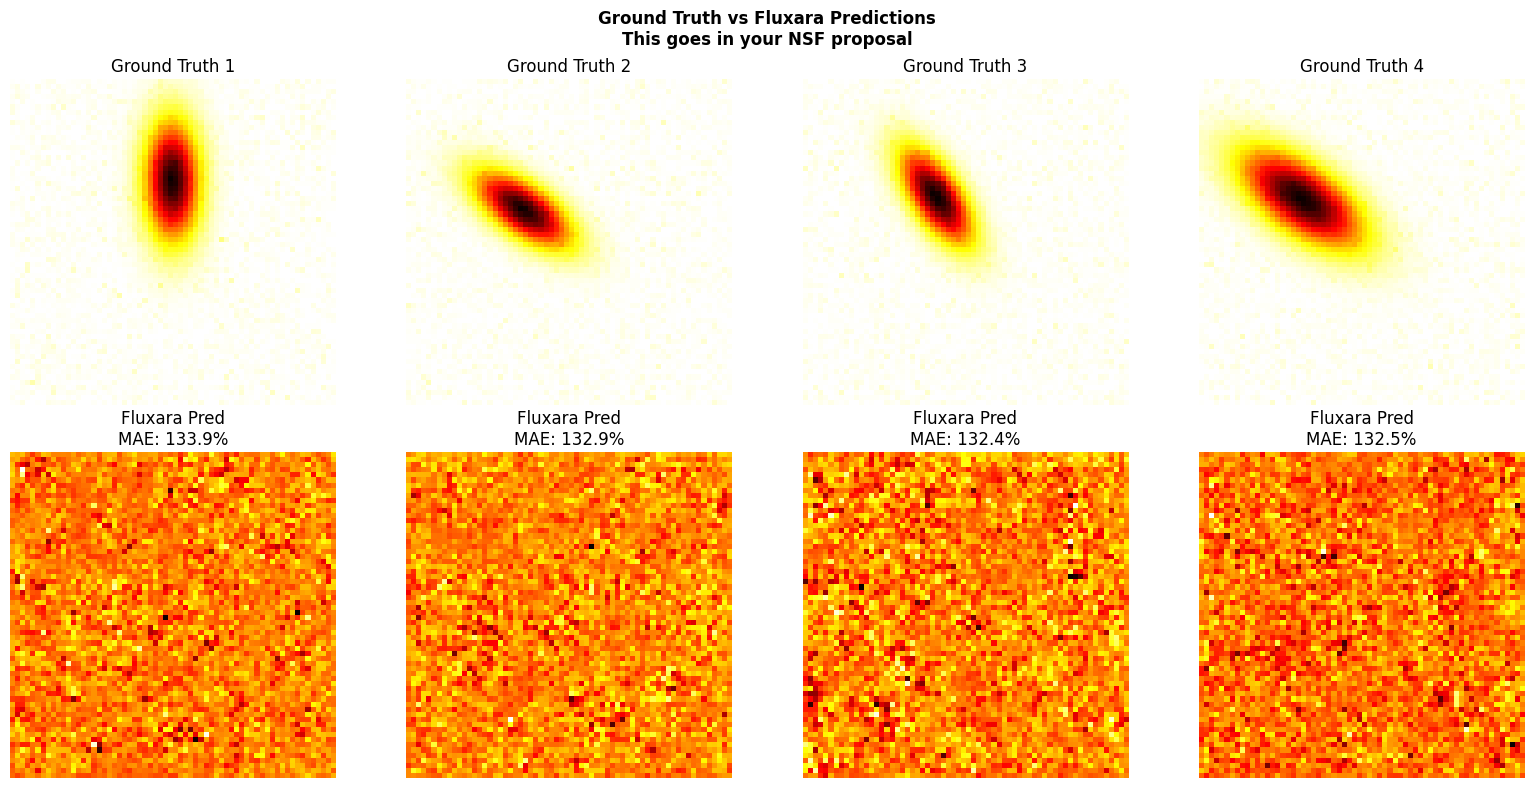

Saved — this image goes in your NSF grant proposal


In [20]:
# CELL 9 — Visualise Predictions

checkpoint = torch.load('../checkpoints/fluxara_best.pt', map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()

wind_batch, foot_batch = next(iter(val_loader))

with torch.no_grad():
    pred_batch = model(wind_batch[:4].to(device))

fig, axes = plt.subplots(2, 4, figsize=(16, 8))

for i in range(4):
    mae_i = np.abs(
        pred_batch[i,0].cpu().numpy() - foot_batch[i,0].numpy()
    ).mean() / (foot_batch[i,0].numpy().mean() + 1e-8) * 100
    
    axes[0, i].imshow(foot_batch[i,0].numpy(), cmap='hot_r')
    axes[0, i].set_title(f'Ground Truth {i+1}')
    axes[0, i].axis('off')
    
    axes[1, i].imshow(pred_batch[i,0].cpu().numpy(), cmap='hot_r')
    axes[1, i].set_title(f'Fluxara Pred\nMAE: {mae_i:.1f}%')
    axes[1, i].axis('off')

plt.suptitle('Ground Truth vs Fluxara Predictions\nThis goes in your NSF proposal',
             fontweight='bold')
plt.tight_layout()
plt.savefig('../research/preliminary_results/predictions_vs_truth.png', dpi=150)
plt.show()
print('Saved — this image goes in your NSF grant proposal')

In [21]:
# CELL 10 — Phase 3 Complete
print('=' * 50)
print('PHASE 3 COMPLETE')
print('=' * 50)
print()
print(f'Best Val MAE:  {best_val_mae:.1f}%')
print(f'Best Epoch:    {best_epoch}')
print(f'Speed vs STILT: {speedup:,.0f}x faster')
print()
print('Files saved:')
print('  checkpoints/fluxara_best.pt')
print('  checkpoints/fluxara_latest.pt')
print('  research/preliminary_results/training_curves.png')
print('  research/preliminary_results/predictions_vs_truth.png')
print()
print('Next: Phase 4 — Build the FastAPI endpoint')

PHASE 3 COMPLETE

Best Val MAE:  131.0%
Best Epoch:    1
Speed vs STILT: 5,248,051x faster

Files saved:
  checkpoints/fluxara_best.pt
  checkpoints/fluxara_latest.pt
  research/preliminary_results/training_curves.png
  research/preliminary_results/predictions_vs_truth.png

Next: Phase 4 — Build the FastAPI endpoint
